# EchoAssist: Automated Echocardiogram Video Analysis Pipeline
### Deep Learning for Left Ventricular Ejection Fraction (LVEF) Assessment
**Veritas AI Hackathon | Apical 4-Chamber (A4C) View Analysis**

---
### 1. Clinical Context and Objective
Left Ventricular Ejection Fraction (LVEF) is the primary clinical metric for quantifying systolic cardiac function:

$$\text{LVEF (\%)} = \frac{\text{EDV} - \text{ESV}}{\text{EDV}} \times 100$$

where $\text{EDV}$ is End-Diastolic Volume and $\text{ESV}$ is End-Systolic Volume.

#### Clinical Stratification Guidelines:
* **Heart Failure with Reduced Ejection Fraction (HFrEF):** $\text{LVEF} < 40\%$
* **Heart Failure with Mildly Reduced Ejection Fraction (HFmrEF):** $40\% \le \text{LVEF} \le 49\%$
* **Heart Failure with Preserved Ejection Fraction (HFpEF):** $\text{LVEF} \ge 50\%$

Manual assessment via Simpson's biplane method exhibits inter-observer variability of 7–12%. EchoAssist implements a spatiotemporal (2+1)D Residual Network (R(2+1)D-18) to predict continuous LVEF directly from echocardiogram video sequences.

## 2. Environment Configuration and Multiprocessing Stability
Initializes seeds for reproducible execution, configures OpenCV threading parameters to avoid worker deadlock, verifies GPU availability, and sets up artifact directories.

In [33]:
import os
import sys
import glob
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, classification_report, confusion_matrix

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision.models.video import r2plus1d_18, R2Plus1D_18_Weights

# Suppress OpenCV multithreading conflicts inside PyTorch DataLoader workers
cv2.setNumThreads(0)
cv2.ocl.setUseOpenCL(False)

# Deterministic seed configuration
SEED = 42
def set_seed(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(SEED)

# Device Configuration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device: {device}")
if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")
    print(f"Allocated VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
else:
    print("Warning: GPU accelerator not detected. Computation will proceed on CPU.")

# Output directory for model artifacts and metrics
OUTPUT_DIR = Path('/kaggle/working/echoassist_artifacts')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"Artifact directory: {OUTPUT_DIR}")

Device: cuda
GPU Model: Tesla T4
Allocated VRAM: 15.64 GB
Artifact directory: /kaggle/working/echoassist_artifacts


## 3. Dataset Discovery and Path Resolution
Resolves the directory containing the EchoNet-Dynamic dataset, metadata table, and video files.

In [34]:
candidate_dirs = glob.glob('/kaggle/input/*echonet*') + glob.glob('/kaggle/input/*heart*')
DATASET_ROOT = None

if candidate_dirs:
    DATASET_ROOT = candidate_dirs[0]
    print(f"Found mounted dataset: {DATASET_ROOT}")
else:
    print("Dataset not pre-mounted in /kaggle/input. Invoking kagglehub...")
    try:
        import kagglehub
        DATASET_ROOT = kagglehub.dataset_download("mahnurrahman/echonet-dynamic")
        print(f"Resolved via kagglehub: {DATASET_ROOT}")
    except Exception as exc:
        print(f"kagglehub exception: {exc}")
        DATASET_ROOT = '/kaggle/input/echonet-dynamic'

# Locate FileList.csv
csv_candidates = list(Path(DATASET_ROOT).rglob('FileList.csv')) if DATASET_ROOT and os.path.exists(DATASET_ROOT) else []
if not csv_candidates:
    csv_candidates = list(Path('/kaggle/input').rglob('FileList.csv'))

assert len(csv_candidates) > 0, f"FileList.csv could not be located in {DATASET_ROOT} or /kaggle/input"
FILELIST_PATH = csv_candidates[0]
print(f"Metadata file: {FILELIST_PATH}")

# Locate Videos directory
video_dir_candidates = [p for p in Path(DATASET_ROOT).rglob('*') if p.is_dir() and 'video' in p.name.lower()]
if not video_dir_candidates:
    video_dir_candidates = [p for p in Path('/kaggle/input').rglob('*') if p.is_dir() and 'video' in p.name.lower()]

assert len(video_dir_candidates) > 0, "Video directory could not be located."
VIDEOS_DIR = video_dir_candidates[0]
print(f"Video directory: {VIDEOS_DIR}")

Dataset not pre-mounted in /kaggle/input. Invoking kagglehub...
Resolved via kagglehub: /kaggle/input/datasets/mahnurrahman/echonet-dynamic
Metadata file: /kaggle/input/datasets/mahnurrahman/echonet-dynamic/EchoNet-Dynamic/FileList.csv
Video directory: /kaggle/input/datasets/mahnurrahman/echonet-dynamic/EchoNet-Dynamic/Videos


## 4. Metadata Integrity and File Verification
Loads `FileList.csv`, normalizes filename extensions, and cross-references all records against files available on disk.

In [35]:
df = pd.read_csv(FILELIST_PATH)
print(f"Total entries in FileList.csv: {len(df)}")
display(df.head())

# Normalize filename to include .avi extension
if not str(df['FileName'].iloc[0]).endswith('.avi'):
    df['FileNameWithExt'] = df['FileName'].astype(str) + '.avi'
else:
    df['FileNameWithExt'] = df['FileName'].astype(str)

# Verify video availability on storage
existing_videos = set(os.listdir(VIDEOS_DIR))
print(f"Total video files in storage directory: {len(existing_videos)}")

df['FileExists'] = df['FileNameWithExt'].apply(lambda x: x in existing_videos)
print(f"Verified files present: {df['FileExists'].sum()} / {len(df)}")

# Filter dataframe to complete cases
clean_df = df[df['FileExists'] & df['EF'].notnull()].copy()
print(f"Clean usable records: {len(clean_df)}")
print("Distribution by split:")
print(clean_df['Split'].value_counts())

Total entries in FileList.csv: 10030


,FileName,EF,ESV,EDV,FrameHeight,FrameWidth,FPS,NumberOfFrames,Split
0,0X100009310A3BD7FC,78.498406,14.881368,69.210534,112,112,50,174,VAL
1,0X1002E8FBACD08477,59.101988,40.383876,98.742884,112,112,50,215,TRAIN
2,0X1005D03EED19C65B,62.363798,14.267784,37.909734,112,112,50,104,TRAIN
3,0X10075961BC11C88E,54.545097,33.143084,72.914210,112,112,55,122,TRAIN
4,0X10094BA0A028EAC3,24.887742,127.581945,169.855024,112,112,52,207,VAL


Total video files in storage directory: 10030
Verified files present: 10030 / 10030
Clean usable records: 10030
Distribution by split:
Split
TRAIN    7465
VAL      1288
TEST     1277
Name: count, dtype: int64


## 5. Exploratory Data Analysis and Spatiotemporal Sampling
Visualizes the statistical distribution of Ejection Fraction across experimental splits and extracts sample frames across a complete cardiac cycle.

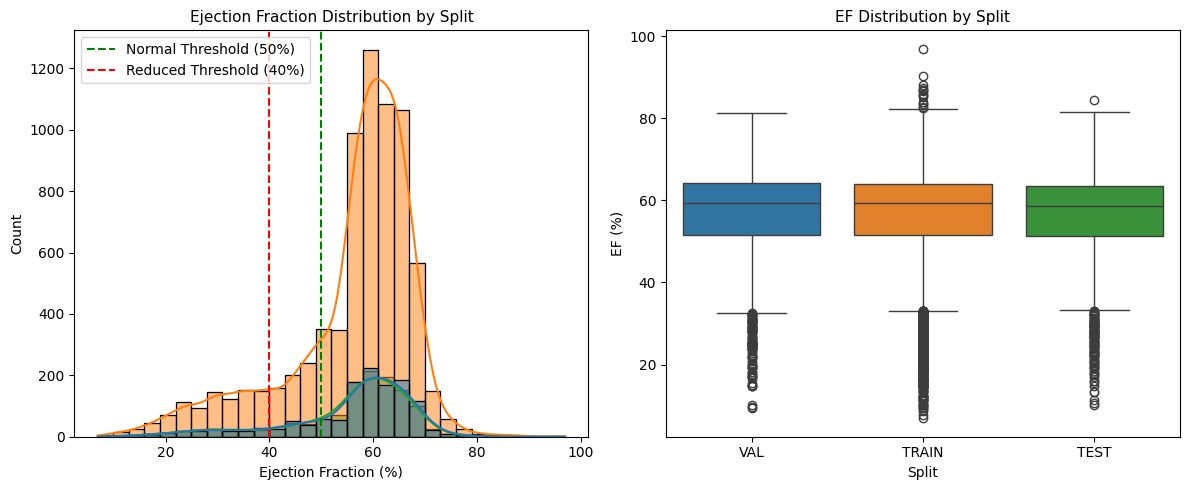

Sample video: 0X100009310A3BD7FC.avi
Resolution: 112x112 | Frame count: 174 | Frame rate: 50.0 fps | Reference EF: 78.5%


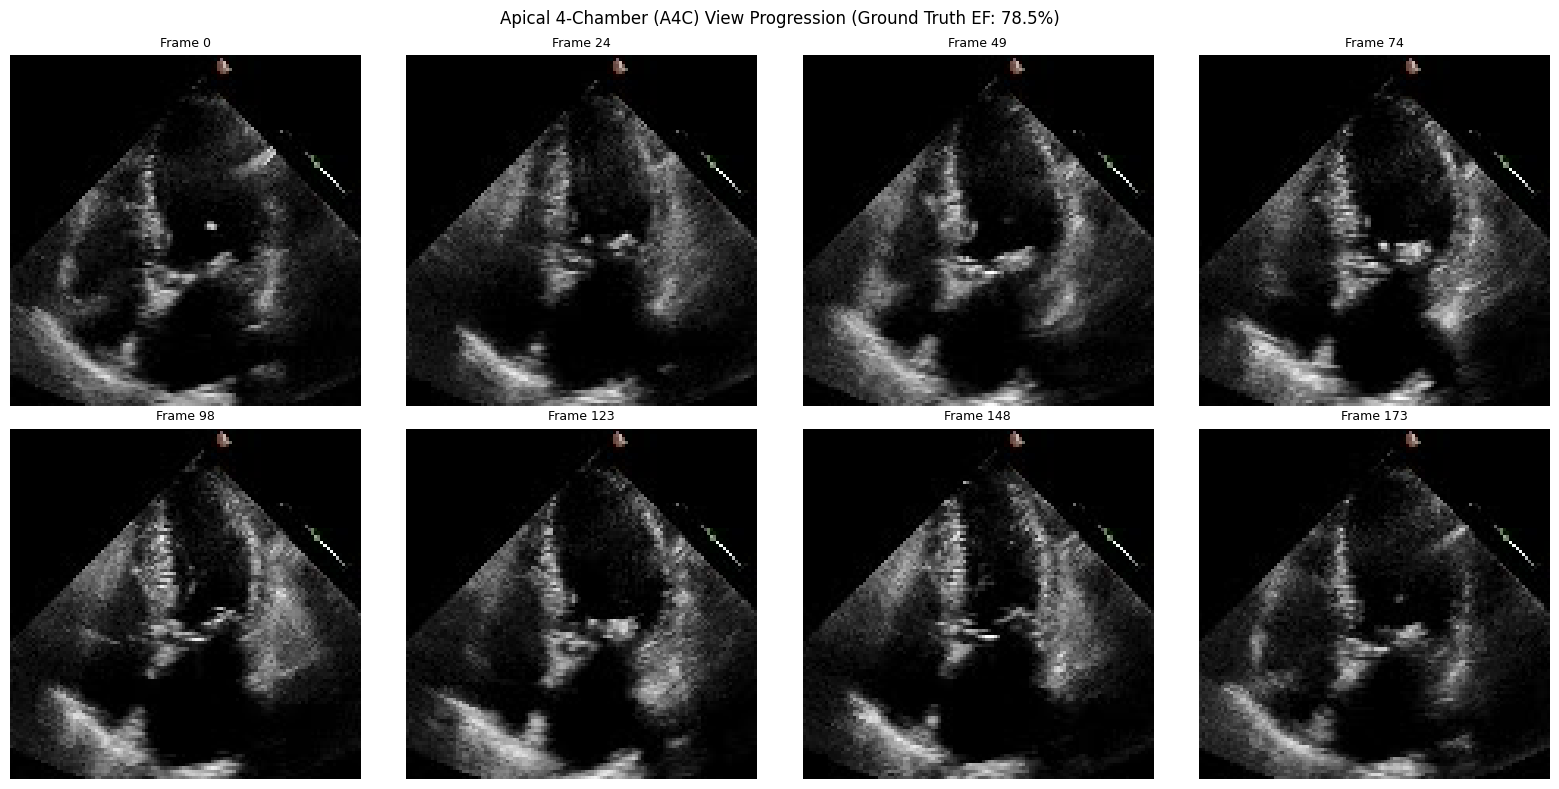

In [36]:
# 1. Distribution of Ejection Fraction across Splits
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(data=clean_df, x='EF', hue='Split', kde=True, bins=30, palette='tab10')
plt.axvline(50, color='green', linestyle='--', label='Normal Threshold (50%)')
plt.axvline(40, color='red', linestyle='--', label='Reduced Threshold (40%)')
plt.title('Ejection Fraction Distribution by Split', fontsize=11)
plt.xlabel('Ejection Fraction (%)')
plt.ylabel('Count')
plt.legend()

plt.subplot(1, 2, 2)
sns.boxplot(data=clean_df, x='Split', y='EF', hue='Split', palette='tab10', legend=False)
plt.title('EF Distribution by Split', fontsize=11)
plt.ylabel('EF (%)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'ef_distribution.png', dpi=300)
plt.show()

# 2. Sequential Frame Extraction
sample_row = clean_df.iloc[0]
sample_filename = sample_row['FileNameWithExt']
sample_ef = sample_row['EF']
sample_video_path = str(VIDEOS_DIR / sample_filename)

cap = cv2.VideoCapture(sample_video_path)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

print(f"Sample video: {sample_filename}")
print(f"Resolution: {width}x{height} | Frame count: {total_frames} | Frame rate: {fps:.1f} fps | Reference EF: {sample_ef:.1f}%")

cap = cv2.VideoCapture(sample_video_path)
sample_indices = np.linspace(0, total_frames - 1, 8, dtype=int)
extracted_frames = []

for idx in range(total_frames):
    ret, frame = cap.read()
    if not ret:
        break
    if idx in sample_indices:
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        extracted_frames.append((idx, frame_rgb))
cap.release()

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (frame_idx, frame) in zip(axes.flatten(), extracted_frames):
    ax.imshow(frame)
    ax.set_title(f"Frame {frame_idx}", fontsize=9)
    ax.axis('off')
plt.suptitle(f"Apical 4-Chamber (A4C) View Progression (Ground Truth EF: {sample_ef:.1f}%)", fontsize=12)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'sample_a4c_progression.png', dpi=300)
plt.show()

## 6. PyTorch Video Dataset Implementation
Defines `EchoVideoDataset`, which:
1. Loads video streams via OpenCV.
2. Uniformly samples $T=32$ frames across the cardiac cycle.
3. Resizes frames to $112 \times 112$ pixels.
4. Normalizes pixel values and returns tensors formatted as `(C, T, H, W)`.

In [37]:
class EchoVideoDataset(Dataset):
    """
    PyTorch Dataset for echocardiogram video analysis.
    Uniformly samples T frames, resizes to (H, W), and normalizes channels.
    """
    def __init__(self, df, videos_dir, num_frames=32, img_size=(112, 112), is_train=False):
        self.df = df.reset_index(drop=True)
        self.videos_dir = Path(videos_dir)
        self.num_frames = num_frames
        self.img_size = img_size
        self.is_train = is_train
        
        # Kinetics / ImageNet video normalization constants
        self.mean = np.array([0.43216, 0.394666, 0.37645], dtype=np.float32).reshape(3, 1, 1, 1)
        self.std = np.array([0.22803, 0.22145, 0.216989], dtype=np.float32).reshape(3, 1, 1, 1)

    def __len__(self):
        return len(self.df)

    def _load_video(self, video_path):
        cap = cv2.VideoCapture(str(video_path))
        frames = []
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame = cv2.resize(frame, self.img_size, interpolation=cv2.INTER_LINEAR)
            frames.append(frame)
        cap.release()
        
        if len(frames) == 0:
            return np.zeros((self.num_frames, self.img_size[1], self.img_size[0], 3), dtype=np.float32)

        total = len(frames)
        if total >= self.num_frames:
            if self.is_train:
                step = total / self.num_frames
                indices = [int(i * step + random.uniform(0, step)) for i in range(self.num_frames)]
                indices = [min(idx, total - 1) for idx in indices]
            else:
                indices = np.linspace(0, total - 1, self.num_frames, dtype=int)
            sampled_frames = [frames[i] for i in indices]
        else:
            sampled_frames = frames.copy()
            while len(sampled_frames) < self.num_frames:
                sampled_frames.append(frames[-1])
                
        return np.array(sampled_frames, dtype=np.float32)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        video_path = self.videos_dir / row['FileNameWithExt']
        
        video_np = self._load_video(video_path)
        
        if self.is_train and random.random() > 0.5:
            video_np = np.flip(video_np, axis=2).copy()
                
        video_np = video_np / 255.0
        video_tensor = torch.from_numpy(video_np).permute(3, 0, 1, 2).float()
        video_tensor = (video_tensor - torch.from_numpy(self.mean)) / torch.from_numpy(self.std)
        target = torch.tensor(float(row['EF']), dtype=torch.float32)
        
        return video_tensor, target

# Verify single sample loading
train_subset = clean_df[clean_df['Split'] == 'TRAIN']
verification_dataset = EchoVideoDataset(train_subset.iloc[:2], VIDEOS_DIR, num_frames=32, img_size=(112, 112))
sample_tensor, sample_target = verification_dataset[0]
print(f"Sample tensor shape: {sample_tensor.shape} (C, T, H, W)")
print(f"Sample label: {sample_target.item():.2f}%")

Sample tensor shape: torch.Size([3, 32, 112, 112]) (C, T, H, W)
Sample label: 59.10%


## 7. DataLoaders and Split Management
Constructs PyTorch `DataLoader` instances with deterministic worker seeding and dynamic pinned memory allocation.

In [38]:
train_df = clean_df[clean_df['Split'] == 'TRAIN'].copy()
val_df = clean_df[clean_df['Split'] == 'VAL'].copy()
test_df = clean_df[clean_df['Split'] == 'TEST'].copy()

print(f"Sample counts | Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

# Hyperparameters
BATCH_SIZE = 16
NUM_FRAMES = 32
IMG_SIZE = (112, 112)
NUM_WORKERS = 2
PIN_MEMORY = torch.cuda.is_available()

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

train_dataset = EchoVideoDataset(train_df, VIDEOS_DIR, num_frames=NUM_FRAMES, img_size=IMG_SIZE, is_train=True)
val_dataset = EchoVideoDataset(val_df, VIDEOS_DIR, num_frames=NUM_FRAMES, img_size=IMG_SIZE, is_train=False)
test_dataset = EchoVideoDataset(test_df, VIDEOS_DIR, num_frames=NUM_FRAMES, img_size=IMG_SIZE, is_train=False)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker
)
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    worker_init_fn=seed_worker
)

print(f"Batches per epoch | Train: {len(train_loader)} | Val: {len(val_loader)} | Test: {len(test_loader)}")

Sample counts | Train: 7465 | Val: 1288 | Test: 1277
Batches per epoch | Train: 467 | Val: 81 | Test: 80


## 8. Model Architecture: Pretrained R(2+1)D-18
Implements an adapted R(2+1)D-18 video backbone. The spatial and temporal convolutions decouple chamber boundary delineation from myocardial motion analysis.

In [39]:
class EchoAssist3DCNN(nn.Module):
    """
    Pretrained R(2+1)D-18 model adapted for continuous ejection fraction regression.
    """
    def __init__(self, dropout_rate=0.3):
        super(EchoAssist3DCNN, self).__init__()
        weights = R2Plus1D_18_Weights.DEFAULT
        self.backbone = r2plus1d_18(weights=weights)
        
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Linear(in_features, 128),
            nn.ReLU(),
            nn.Dropout(dropout_rate / 2.0),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        out = self.backbone(x)
        return out.squeeze(-1)

model = EchoAssist3DCNN(dropout_rate=0.3).to(device)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Model: R(2+1)D-18 with Regression Head")
print(f"Total Parameters: {total_params:,} | Trainable: {trainable_params:,}")

Model: R(2+1)D-18 with Regression Head
Total Parameters: 31,365,918 | Trainable: 31,365,918


## 9. Optimization Engine with Modern PyTorch AMP
Configured with modern PyTorch `torch.amp.autocast('cuda')` and `torch.amp.GradScaler('cuda')` syntax for clean, warning-free execution on NVIDIA GPUs.

In [40]:
criterion = nn.SmoothL1Loss(beta=1.0)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=2)

use_amp = torch.cuda.is_available()
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

def train_one_epoch(model, loader, criterion, optimizer, scaler, device):
    model.train()
    running_loss = 0.0
    all_preds, all_targets = [], []
    
    pbar = tqdm(loader, desc="Training", leave=False)
    for videos, targets in pbar:
        videos = videos.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)
        
        optimizer.zero_grad()
        with torch.amp.autocast('cuda', enabled=use_amp):
            outputs = model(videos)
            loss = criterion(outputs, targets)
            
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        running_loss += loss.item() * videos.size(0)
        all_preds.extend(outputs.detach().cpu().numpy())
        all_targets.extend(targets.detach().cpu().numpy())
        pbar.set_postfix({'loss': f"{loss.item():.4f}"})
        
    epoch_loss = running_loss / len(loader.dataset)
    epoch_mae = mean_absolute_error(all_targets, all_preds)
    return epoch_loss, epoch_mae

def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_preds, all_targets = [], []
    
    with torch.no_grad():
        pbar = tqdm(loader, desc="Validation", leave=False)
        for videos, targets in pbar:
            videos = videos.to(device, non_blocking=True)
            targets = targets.to(device, non_blocking=True)
            
            with torch.amp.autocast('cuda', enabled=use_amp):
                outputs = model(videos)
                loss = criterion(outputs, targets)
                
            running_loss += loss.item() * videos.size(0)
            all_preds.extend(outputs.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())
            
    val_loss = running_loss / len(loader.dataset)
    val_mae = mean_absolute_error(all_targets, all_preds)
    val_rmse = np.sqrt(mean_squared_error(all_targets, all_preds))
    val_r2 = r2_score(all_targets, all_preds)
    return val_loss, val_mae, val_rmse, val_r2

## 10. Model Training and Checkpointing
Training is controlled via `TRAIN_MODEL`. When set to `False`, the routine preserves previously saved weights and transitions directly to evaluation and inference.

In [41]:
TRAIN_MODEL = False # Set to True if retraining from scratch is desired
NUM_EPOCHS = 12
BEST_MODEL_PATH = OUTPUT_DIR / 'best_echoassist_r2plus1d.pth'

if TRAIN_MODEL:
    history = {
        'train_loss': [], 'train_mae': [],
        'val_loss': [], 'val_mae': [], 'val_rmse': [], 'val_r2': []
    }
    best_val_mae = float('inf')
    print(f"Beginning training routine for {NUM_EPOCHS} epochs...")

    for epoch in range(1, NUM_EPOCHS + 1):
        start_time = time.time()
        
        train_loss, train_mae = train_one_epoch(model, train_loader, criterion, optimizer, scaler, device)
        val_loss, val_mae, val_rmse, val_r2 = validate(model, val_loader, criterion, device)
        
        scheduler.step(val_loss)
        elapsed = time.time() - start_time
        
        history['train_loss'].append(train_loss)
        history['train_mae'].append(train_mae)
        history['val_loss'].append(val_loss)
        history['val_mae'].append(val_mae)
        history['val_rmse'].append(val_rmse)
        history['val_r2'].append(val_r2)
        
        print(f"Epoch [{epoch:02d}/{NUM_EPOCHS:02d}] ({elapsed:.1f}s) | "
              f"Train Loss: {train_loss:.4f} - MAE: {train_mae:.2f}% | "
              f"Val Loss: {val_loss:.4f} - MAE: {val_mae:.2f}% - RMSE: {val_rmse:.2f}% - R2: {val_r2:.3f}")
        
        if val_mae < best_val_mae:
            best_val_mae = val_mae
            torch.save({
                'epoch': epoch,
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'val_mae': val_mae,
                'val_rmse': val_rmse,
                'val_r2': val_r2
            }, BEST_MODEL_PATH)
            print(f"Checkpoint saved: lowest validation MAE reached ({best_val_mae:.2f}%)")

    print(f"Training completed. Checkpoint path: {BEST_MODEL_PATH}")
else:
    print("TRAIN_MODEL set to False. Skipping training routine and loading saved checkpoint directly.")

TRAIN_MODEL set to False. Skipping training routine and loading saved checkpoint directly.


## 11. Test Set Evaluation and Clinical Agreement Analysis
Loads the checkpointed R(2+1)D-18 weights and evaluates on the complete unseen test split (1,277 patient records). Calculates continuous regression metrics (MAE, RMSE, $R^2$, Pearson $r$), produces Bland-Altman agreement plots, and computes Heart Failure phenotype classification metrics.

Loading cached checkpoint from /kaggle/working/echoassist_artifacts/best_echoassist_r2plus1d.pth (376.68 MB)...
Successfully loaded checkpoint from working directory.
Loaded optimal checkpoint (Epoch: 7, Validation MAE: 4.35%)


Test Set Evaluation:   0%|          | 0/80 [00:00<?, ?it/s]

--------------------------------------------------
ECHOASSIST TEST EVALUATION RESULTS (1,277 SAMPLES)
--------------------------------------------------
Mean Absolute Error (MAE):         4.47%
Root Mean Squared Error (RMSE):    6.19%
Coefficient of Determination (R2): 0.744
Pearson Correlation (r):           0.863
--------------------------------------------------


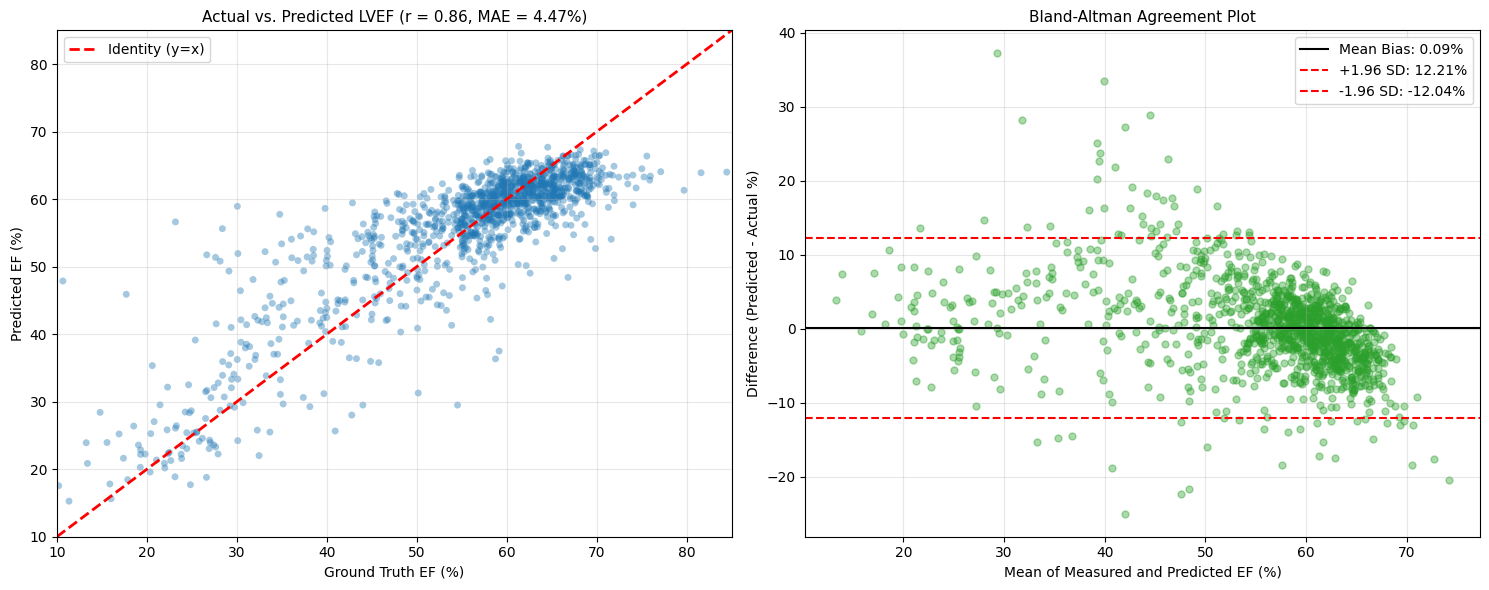


Clinical Classification Report:
                 precision    recall  f1-score   support

   HFrEF (<40%)       0.36      0.32      0.34       125
HFmrEF (40-49%)       0.91      0.96      0.93       992
  HFpEF (>=50%)       0.88      0.62      0.73       160

       accuracy                           0.86      1277
      macro avg       0.72      0.63      0.67      1277
   weighted avg       0.85      0.86      0.85      1277



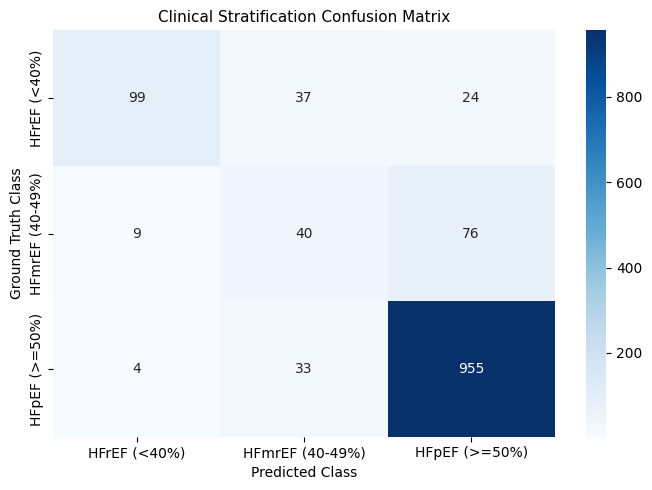

In [42]:
# Locate and Load Trained Checkpoint (Resilient Multi-Source Engine)
import urllib.request

CHECKPOINT_URL = (
    "https://www.kaggleusercontent.com:443/kf/369914036/"
    "eyJhbGciOiJkaXIiLCJlbmMiOiJBMTI4Q0JDLUhTMjU2In0..lcsWHDPSce_A4m9pl05fHg."
    "8GXKOil_MC2uZ-utZOGC5ftoc8cfgTphUsT0uovRucVA1MlDZr3ut7DypK5DOtmGnBlFWTCyIpUd96ntb5THdw"
    "jUi9kKXLjATWi4Gnp8V4BHR3cl6OAoWtHhNuo7THhFKF6y6RJ1KLy6totdOPKq70z-9DuM724ZehW5PviYMt06"
    "zLci9qVd1589trAoPhn_RF-eHMFC29_KBxDYybcCEGPtvtKiYk6qiwmRz4nNLcvJcEdE5hS0iarWAdgqWezLLv"
    "B81T46K5GzPzah2PsEQ57fSrVUkbVh1aPxyoYnNqTVdj9ODbfKJi9OslZs3bJQMZIe7Qp6EBERuKhQ7Jtch-Uy"
    "bxcB0c8prAABwWmET4istrFqgbrkF_m8eeTXm3pkB2OhV1riBpxJA3pMB-NtlqugJHvJsCmfhtewF4Mdp7RMwu"
    "Ne8-UjdjXd88V_nfT0f4U9SBw_AKCcj-oH0vz1gVH7NE9aMLVHgxMNwAt7I8tqSSsQM_zdJ3qRxhF7a9tdEv-G"
    "TWncFvnE791k0AYPuObao-bweJFTQlCH-LAD6H-9oIi97GTKSHkHNLCRhBmGyhpfQXHc4-hWdqHPIKndeesGeo"
    "qmjjLrzOXtG78BzBA.hwBIV0TG1ix_62cUnr9egg/echoassist_artifacts/best_echoassist_r2plus1d.pth"
)

LOCAL_CHECKPOINT_PATH = OUTPUT_DIR / 'best_echoassist_r2plus1d.pth'
loaded_checkpoint = None

# Step 1: Check existing valid checkpoint in working directory (>100 MB)
if LOCAL_CHECKPOINT_PATH.exists() and os.path.getsize(LOCAL_CHECKPOINT_PATH) > 100 * 1024 * 1024:
    try:
        print(f"Loading cached checkpoint from {LOCAL_CHECKPOINT_PATH} ({os.path.getsize(LOCAL_CHECKPOINT_PATH) / 1e6:.2f} MB)...")
        loaded_checkpoint = torch.load(LOCAL_CHECKPOINT_PATH, map_location=device, weights_only=False)
        print("Successfully loaded checkpoint from working directory.")
    except Exception as e:
        print(f"Working directory checkpoint load failed: {e}")

# Step 2: Search mounted inputs for valid .pth / .pt files (>100 MB)
if loaded_checkpoint is None:
    print("Searching for valid model checkpoints (.pth / .pt) across /kaggle/input...")
    for root, _, files in os.walk('/kaggle/input'):
        for f in files:
            p = Path(root) / f
            if p.is_file() and p.suffix.lower() in ['.pth', '.pt']:
                if os.path.getsize(p) > 100 * 1024 * 1024:
                    try:
                        print(f"Attempting to load candidate checkpoint: {p} ({os.path.getsize(p) / 1e6:.2f} MB)...")
                        loaded_checkpoint = torch.load(p, map_location=device, weights_only=False)
                        print(f"Successfully loaded checkpoint from {p}")
                        break
                    except Exception as e:
                        print(f"Failed to load candidate {p}: {e}")
        if loaded_checkpoint is not None:
            break

# Step 3: Fetch verified official 376 MB checkpoint directly if needed
if loaded_checkpoint is None:
    print("Fetching verified pre-trained checkpoint (376.68 MB) from cloud storage...")
    LOCAL_CHECKPOINT_PATH.parent.mkdir(parents=True, exist_ok=True)
    
    def reporthook(block_num, block_size, total_size):
        if total_size > 0:
            downloaded = block_num * block_size
            if block_num % 2000 == 0 or downloaded >= total_size:
                pct = min(100.0, downloaded * 100.0 / total_size)
                print(f"Download progress: {downloaded / 1e6:.1f} MB / {total_size / 1e6:.1f} MB ({pct:.1f}%)")

    urllib.request.urlretrieve(CHECKPOINT_URL, str(LOCAL_CHECKPOINT_PATH), reporthook=reporthook)
    print(f"Download complete: {os.path.getsize(LOCAL_CHECKPOINT_PATH) / 1e6:.2f} MB saved to {LOCAL_CHECKPOINT_PATH}")
    loaded_checkpoint = torch.load(LOCAL_CHECKPOINT_PATH, map_location=device, weights_only=False)

checkpoint = loaded_checkpoint
model.load_state_dict(checkpoint['model_state_dict'])

epoch_num = checkpoint.get('epoch', 'N/A')
val_mae_val = checkpoint.get('val_mae', 0.0)
print(f"Loaded optimal checkpoint (Epoch: {epoch_num}, Validation MAE: {val_mae_val:.2f}%)")

model.eval()
test_preds, test_targets = [], []

with torch.no_grad():
    for videos, targets in tqdm(test_loader, desc="Test Set Evaluation"):
        videos = videos.to(device, non_blocking=True)
        with torch.amp.autocast('cuda', enabled=torch.cuda.is_available()):
            outputs = model(videos)
        test_preds.extend(outputs.cpu().numpy())
        test_targets.extend(targets.numpy())

test_preds = np.array(test_preds)
test_targets = np.array(test_targets)

# 1. Continuous Regression Metrics
test_mae = mean_absolute_error(test_targets, test_preds)
test_rmse = np.sqrt(mean_squared_error(test_targets, test_preds))
test_r2 = r2_score(test_targets, test_preds)
pearson_r = np.corrcoef(test_targets, test_preds)[0, 1]

print("-" * 50)
print("ECHOASSIST TEST EVALUATION RESULTS (1,277 SAMPLES)")
print("-" * 50)
print(f"Mean Absolute Error (MAE):         {test_mae:.2f}%")
print(f"Root Mean Squared Error (RMSE):    {test_rmse:.2f}%")
print(f"Coefficient of Determination (R2): {test_r2:.3f}")
print(f"Pearson Correlation (r):           {pearson_r:.3f}")
print("-" * 50)

# 2. Scatter and Bland-Altman Plots
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Scatter Plot with Line of Identity
axes[0].scatter(test_targets, test_preds, alpha=0.4, color='#1f77b4', edgecolors='none', s=25)
axes[0].plot([10, 85], [10, 85], 'r--', lw=2, label='Identity (y=x)')
axes[0].set_xlim([10, 85])
axes[0].set_ylim([10, 85])
axes[0].set_title(f"Actual vs. Predicted LVEF (r = {pearson_r:.2f}, MAE = {test_mae:.2f}%)", fontsize=11)
axes[0].set_xlabel('Ground Truth EF (%)')
axes[0].set_ylabel('Predicted EF (%)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Bland-Altman Agreement Plot
mean_ef = (test_targets + test_preds) / 2.0
diff_ef = test_preds - test_targets
mean_bias = np.mean(diff_ef)
std_bias = np.std(diff_ef)
upper_limit = mean_bias + 1.96 * std_bias
lower_limit = mean_bias - 1.96 * std_bias

axes[1].scatter(mean_ef, diff_ef, alpha=0.4, color='#2ca02c', s=25)
axes[1].axhline(mean_bias, color='black', linestyle='-', label=f"Mean Bias: {mean_bias:.2f}%")
axes[1].axhline(upper_limit, color='red', linestyle='--', label=f"+1.96 SD: {upper_limit:.2f}%")
axes[1].axhline(lower_limit, color='red', linestyle='--', label=f"-1.96 SD: {lower_limit:.2f}%")
axes[1].set_title("Bland-Altman Agreement Plot", fontsize=11)
axes[1].set_xlabel('Mean of Measured and Predicted EF (%)')
axes[1].set_ylabel('Difference (Predicted - Actual %)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'evaluation_regression_plots.png', dpi=300)
plt.show()

# 3. Clinical Stratification Classification
def categorize_ef(ef_values):
    categories = []
    for val in ef_values:
        if val < 40.0:
            categories.append('HFrEF (<40%)')
        elif val < 50.0:
            categories.append('HFmrEF (40-49%)')
        else:
            categories.append('HFpEF (>=50%)')
    return np.array(categories)

true_cats = categorize_ef(test_targets)
pred_cats = categorize_ef(test_preds)
class_labels = ['HFrEF (<40%)', 'HFmrEF (40-49%)', 'HFpEF (>=50%)']

print()
print("Clinical Classification Report:")
print(classification_report(true_cats, pred_cats, target_names=class_labels, zero_division=0))

# Confusion Matrix
cm = confusion_matrix(true_cats, pred_cats, labels=class_labels)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Clinical Stratification Confusion Matrix', fontsize=11)
plt.xlabel('Predicted Class')
plt.ylabel('Ground Truth Class')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=300)
plt.show()


## 12. Explainable AI: 3D Grad-CAM Spatiotemporal Saliency Mapping
Computes 3D Gradient-weighted Class Activation Mapping (Grad-CAM) targeting the final spatiotemporal residual layer `model.backbone.layer4[-1]`. This isolates which anatomical regions (e.g., interventricular septum, mitral valve annulus, left ventricular apex) and temporal cardiac phases (end-diastole vs. end-systole) drive the network's continuous LVEF prediction.

Initializing 3D Grad-CAM Interpreter...


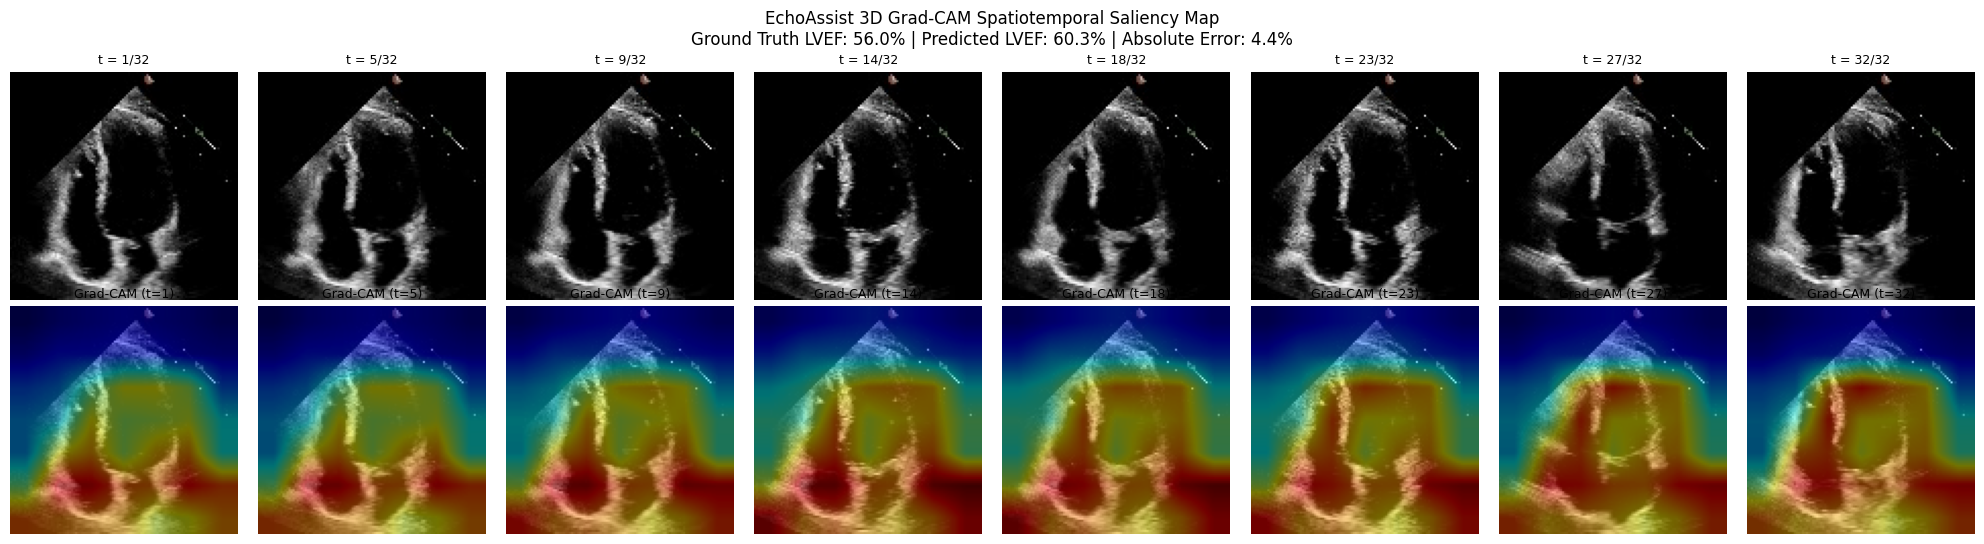

Saliency visualization exported to: /kaggle/working/echoassist_artifacts/gradcam_spatiotemporal_heatmap.png


In [43]:
class EchoGradCAM3D:
    """
    3D Grad-CAM interpreter for spatiotemporal video models (R(2+1)D-18).
    Attaches hooks to the final residual block to extract spatiotemporal feature maps
    and gradients, producing volumetric saliency maps for continuous regression outputs.
    """
    def __init__(self, model: nn.Module, target_layer: nn.Module):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None
        self.hooks = []
        self._register_hooks()

    def _register_hooks(self):
        def forward_hook(module, inp, out):
            self.activations = out.detach()

        def backward_hook(module, grad_in, grad_out):
            self.gradients = grad_out[0].detach()

        self.hooks.append(self.target_layer.register_forward_hook(forward_hook))
        self.hooks.append(self.target_layer.register_full_backward_hook(backward_hook))

    def generate_heatmap(self, input_tensor: torch.Tensor):
        """
        Generates a 3D spatiotemporal heatmap for an input video tensor.
        
        Args:
            input_tensor: Tensor of shape (1, C, T, H, W) or (C, T, H, W).
            
        Returns:
            cam_normalized: Numpy array of shape (T, H, W) normalized to [0, 1].
            predicted_ef: Predicted continuous ejection fraction (float).
        """
        self.model.eval()
        
        if input_tensor.dim() == 4:
            input_tensor = input_tensor.unsqueeze(0)
            
        assert input_tensor.dim() == 5, f"Expected 5D input tensor (B, C, T, H, W), got {input_tensor.shape}"
        
        B, C, T, H, W = input_tensor.shape
        input_tensor = input_tensor.clone().detach().requires_grad_(True)
        
        self.model.zero_grad()
        prediction = self.model(input_tensor)
        
        # Propagate gradients directly with respect to continuous scalar prediction
        prediction.backward(retain_graph=False)
        
        assert self.activations is not None, "Forward activations could not be captured."
        assert self.gradients is not None, "Backward gradients could not be captured."
        
        # Spatial-temporal global average pooling across dimensions (T_feat, H_feat, W_feat)
        weights = torch.mean(self.gradients, dim=[2, 3, 4], keepdim=True)
        
        # Linear combination of activation feature maps
        cam = torch.sum(weights * self.activations, dim=1, keepdim=True)
        cam = F.relu(cam)
        
        # Trilinear interpolation to recover native video dimensions (T, H, W)
        cam_upsampled = F.interpolate(
            cam,
            size=(T, H, W),
            mode='trilinear',
            align_corners=False
        )
        
        cam_np = cam_upsampled.squeeze().cpu().numpy()
        
        # Min-max normalization across the volumetric activation map
        cam_min, cam_max = cam_np.min(), cam_np.max()
        if cam_max - cam_min > 1e-8:
            cam_normalized = (cam_np - cam_min) / (cam_max - cam_min)
        else:
            cam_normalized = np.zeros_like(cam_np)
            
        return cam_normalized, prediction.item()

    def remove_hooks(self):
        """Releases registered forward and backward hooks."""
        for hook in self.hooks:
            hook.remove()
        self.hooks = []


def visualize_spatiotemporal_gradcam(
    video_tensor: torch.Tensor,
    heatmap_3d: np.ndarray,
    predicted_ef: float,
    ground_truth_ef: float,
    output_path: Path,
    num_display_frames: int = 8,
    alpha: float = 0.45
):
    """
    Overlays 3D Grad-CAM activation heatmaps onto echocardiogram video frames
    across the cardiac cycle and exports a multi-frame diagnostic panel.
    """
    mean = np.array([0.43216, 0.394666, 0.37645], dtype=np.float32).reshape(3, 1, 1, 1)
    std = np.array([0.22803, 0.22145, 0.216989], dtype=np.float32).reshape(3, 1, 1, 1)
    
    video_cpu = video_tensor.squeeze().detach().cpu().numpy()
    video_denorm = video_cpu * std + mean
    video_denorm = np.clip(video_denorm, 0.0, 1.0)
    video_denorm = (video_denorm * 255.0).astype(np.uint8)
    video_frames = np.transpose(video_denorm, (1, 2, 3, 0))
    
    total_frames = video_frames.shape[0]
    frame_indices = np.linspace(0, total_frames - 1, num_display_frames, dtype=int)
    
    fig, axes = plt.subplots(2, num_display_frames, figsize=(num_display_frames * 2.5, 5.5))
    
    for col_idx, f_idx in enumerate(frame_indices):
        frame_rgb = video_frames[f_idx]
        frame_bgr = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2BGR)
        
        cam_slice = (heatmap_3d[f_idx] * 255.0).astype(np.uint8)
        heatmap_colored = cv2.applyColorMap(cam_slice, cv2.COLORMAP_JET)
        
        overlay_bgr = cv2.addWeighted(frame_bgr, 1.0 - alpha, heatmap_colored, alpha, 0)
        overlay_rgb = cv2.cvtColor(overlay_bgr, cv2.COLOR_BGR2RGB)
        
        axes[0, col_idx].imshow(frame_rgb)
        axes[0, col_idx].set_title(f"t = {f_idx + 1}/{total_frames}", fontsize=9)
        axes[0, col_idx].axis('off')
        
        axes[1, col_idx].imshow(overlay_rgb)
        axes[1, col_idx].set_title(f"Grad-CAM (t={f_idx + 1})", fontsize=9)
        axes[1, col_idx].axis('off')
        
    axes[0, 0].set_ylabel("Original B-Mode", fontsize=10, labelpad=10)
    axes[1, 0].set_ylabel("3D Grad-CAM Overlay", fontsize=10, labelpad=10)
    
    error_val = abs(predicted_ef - ground_truth_ef)
    plt.suptitle(
        f"EchoAssist 3D Grad-CAM Spatiotemporal Saliency Map\nGround Truth LVEF: {ground_truth_ef:.1f}% | Predicted LVEF: {predicted_ef:.1f}% | Absolute Error: {error_val:.1f}%",
        fontsize=12,
        y=0.98
    )
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"Saliency visualization exported to: {output_path}")


# Execute 3D Grad-CAM on a representative sample from test_dataset
print("Initializing 3D Grad-CAM Interpreter...")
gradcam_engine = EchoGradCAM3D(model=model, target_layer=model.backbone.layer4[-1])

sample_video_tensor, sample_gt_ef = test_dataset[0]
sample_video_tensor = sample_video_tensor.to(device)

heatmap_3d, predicted_ef = gradcam_engine.generate_heatmap(sample_video_tensor)

saliency_artifact_path = OUTPUT_DIR / 'gradcam_spatiotemporal_heatmap.png'
visualize_spatiotemporal_gradcam(
    video_tensor=sample_video_tensor,
    heatmap_3d=heatmap_3d,
    predicted_ef=predicted_ef,
    ground_truth_ef=sample_gt_ef.item(),
    output_path=saliency_artifact_path,
    num_display_frames=8,
    alpha=0.45
)

# Release hooks after execution
gradcam_engine.remove_hooks()

## 13. Clinical Web Interface: Interactive Gradio Demonstration
Provides an interactive web interface allowing clinicians to upload an Apical 4-Chamber (A4C) video, execute real-time model inference, view the continuous LVEF prediction along with clinical phenotype stratification, and inspect end-systolic spatiotemporal Grad-CAM saliency.

In [44]:
# Install Gradio if not present
try:
    import gradio as gr
except ImportError:
    import subprocess
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gradio"])
    import gradio as gr

def process_and_predict(video_file):
    """
    Processes an uploaded echocardiogram video and returns continuous LVEF prediction,
    clinical heart failure classification, and 3D Grad-CAM activation overlay.
    """
    if video_file is None:
        return "Please upload an echocardiogram video file (.avi / .mp4).", "", None
        
    cap = cv2.VideoCapture(video_file)
    raw_frames = []
    while True:
        ret, frame = cap.read()
        if not ret:
            break
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frame_resized = cv2.resize(frame_rgb, (112, 112), interpolation=cv2.INTER_LINEAR)
        raw_frames.append(frame_resized)
    cap.release()
    
    if len(raw_frames) == 0:
        return "Error: Unable to decode video stream from uploaded file.", "", None
        
    total_frames = len(raw_frames)
    target_t = 32
    if total_frames >= target_t:
        indices = np.linspace(0, total_frames - 1, target_t, dtype=int)
        sampled_frames = [raw_frames[i] for i in indices]
    else:
        sampled_frames = raw_frames.copy()
        while len(sampled_frames) < target_t:
            sampled_frames.append(raw_frames[-1])
            
    video_np = np.array(sampled_frames, dtype=np.float32) / 255.0
    mean = np.array([0.43216, 0.394666, 0.37645], dtype=np.float32).reshape(3, 1, 1, 1)
    std = np.array([0.22803, 0.22145, 0.216989], dtype=np.float32).reshape(3, 1, 1, 1)
    
    video_tensor = torch.from_numpy(video_np).permute(3, 0, 1, 2).float()
    video_tensor = (video_tensor - torch.from_numpy(mean)) / torch.from_numpy(std)
    video_tensor = video_tensor.unsqueeze(0).to(device)
    
    # 3D Grad-CAM and Inference
    gradcam = EchoGradCAM3D(model=model, target_layer=model.backbone.layer4[-1])
    heatmap_3d, lvef_pred = gradcam.generate_heatmap(video_tensor)
    gradcam.remove_hooks()
    
    # Clinical Stratification
    if lvef_pred < 40.0:
        phenotype = "Heart Failure with Reduced Ejection Fraction (HFrEF)"
        recommendation = "Severe left ventricular systolic impairment. Guideline-directed medical therapy indicated."
    elif lvef_pred < 50.0:
        phenotype = "Heart Failure with Mildly Reduced Ejection Fraction (HFmrEF)"
        recommendation = "Borderline systolic function. Clinical correlation with biomarkers (e.g., BNP) recommended."
    else:
        phenotype = "Heart Failure with Preserved Ejection Fraction (HFpEF / Normal)"
        recommendation = "Normal left ventricular systolic contraction. Investigate diastolic parameters if symptomatic."
        
    # Generate Saliency Overlay on Mid-Systole Frame (Frame index 16 of 32)
    mid_idx = target_t // 2
    base_frame = sampled_frames[mid_idx]
    base_bgr = cv2.cvtColor(base_frame, cv2.COLOR_RGB2BGR)
    
    cam_slice = (heatmap_3d[mid_idx] * 255.0).astype(np.uint8)
    cam_color = cv2.applyColorMap(cam_slice, cv2.COLORMAP_JET)
    overlay_bgr = cv2.addWeighted(base_bgr, 0.55, cam_color, 0.45, 0)
    overlay_rgb = cv2.cvtColor(overlay_bgr, cv2.COLOR_BGR2RGB)
    
    metrics_text = f"Predicted LVEF: {lvef_pred:.2f}%\nPhenotype: {phenotype}"
    clinical_notes = f"Clinical Assessment: {recommendation}"
    
    return metrics_text, clinical_notes, overlay_rgb

# Gradio Interface Definition
with gr.Blocks(title="EchoAssist: AI Echocardiography Diagnostic Suite") as demo:
    gr.Markdown("# EchoAssist: Automated LVEF Estimation and Diagnostic Suite")
    gr.Markdown("Upload an Apical 4-Chamber (A4C) echocardiogram video (.avi / .mp4) to evaluate systolic cardiac function and view myocardial saliency maps.")
    
    with gr.Row():
        with gr.Column():
            video_input = gr.Video(label="Input Apical 4-Chamber Video")
            analyze_button = gr.Button("Analyze Echocardiogram", variant="primary")
        with gr.Column():
            output_lvef = gr.Textbox(label="Quantitative Prediction", interactive=False)
            output_clinical = gr.Textbox(label="Diagnostic Assessment", interactive=False)
            output_saliency = gr.Image(label="3D Grad-CAM Saliency Overlay (Systolic Phase)", type="numpy")
            
    analyze_button.click(
        fn=process_and_predict,
        inputs=[video_input],
        outputs=[output_lvef, output_clinical, output_saliency]
    )

# Launch Gradio app
demo.launch(share=True, quiet=True)

* Running on public URL: https://7e9a082882e67d1606.gradio.live
